In [ ]:
print("hello world")


hello world


1. Loading Dataset and Tokenizer (Sampling 15000 rows)...


README.md: 0.00B [00:00, ?B/s]

MetaMathQA-395K.json:   0%|          | 0.00/396M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/395000 [00:00<?, ? examples/s]


2. Applying Output Standardization...
Rows missing '####' delimiter: 0 (0.00% failure rate)

3. Calculating Token Length Distributions...


100%|██████████| 15000/15000 [00:14<00:00, 1010.80it/s]



Token Length Percentiles:
       prompt_tokens  completion_tokens  total_tokens
count   15000.000000       15000.000000  15000.000000
mean      108.999200         161.025200    270.024400
std        35.137215          97.312894    113.838021
min        53.000000           6.000000     59.000000
50%       103.000000         136.000000    242.000000
90%       141.000000         276.000000    409.000000
95%       157.000000         335.000000    473.000000
99%       221.010000         519.010000    688.000000
max       887.000000        1212.000000   1343.000000

4. Plotting Distributions...


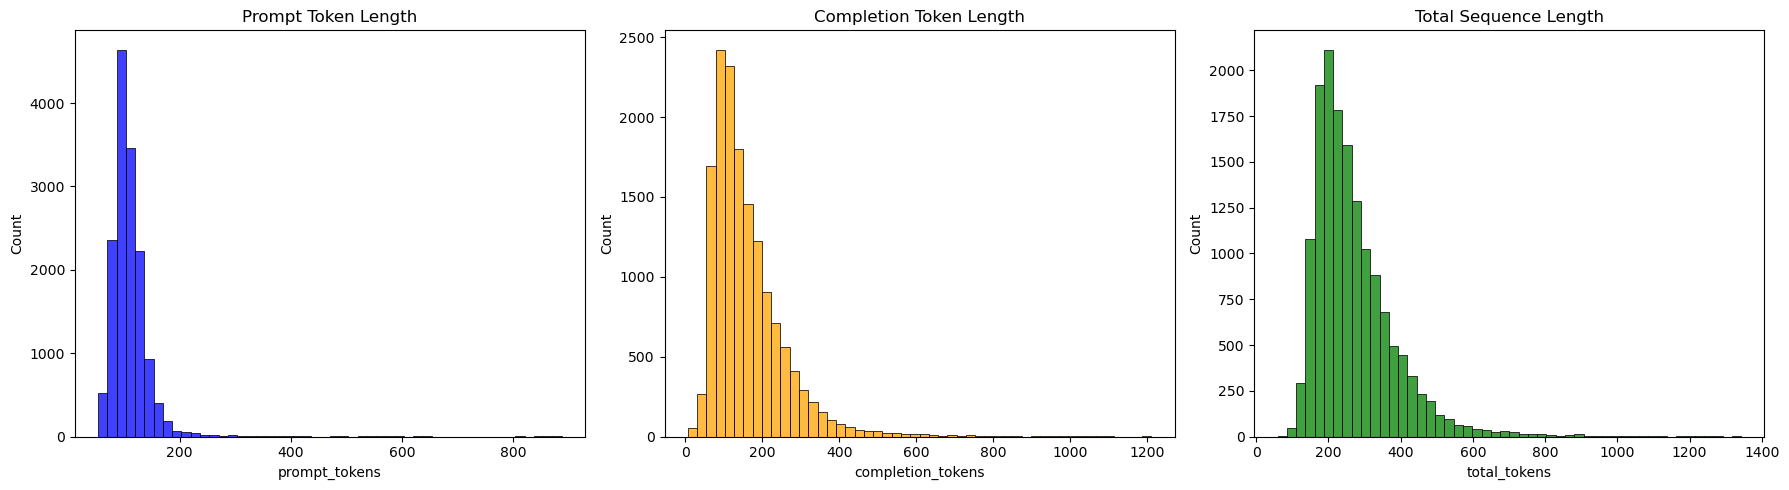


5. Vocabulary Frequency Analysis (Router Prep)...


C:\Users\ozgur\AppData\Local\Temp\ipykernel_8896\2324288919.py:116: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette="viridis")


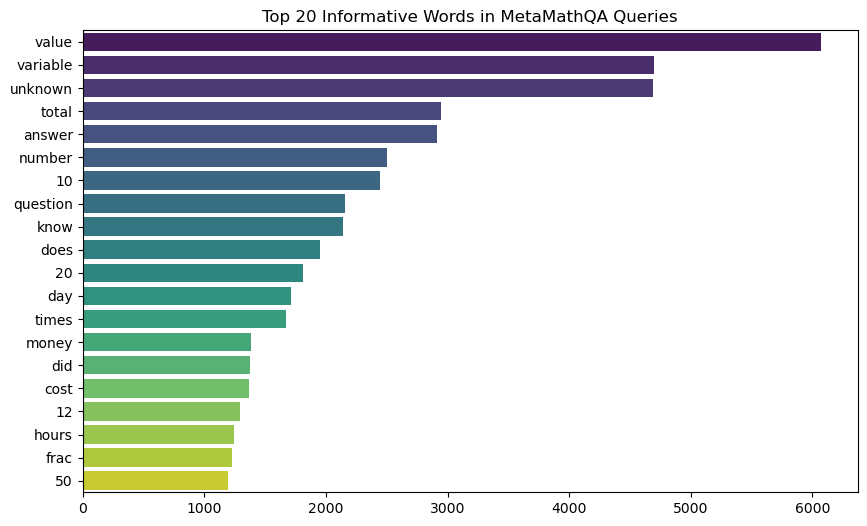


6. Displaying 100 Standardized Examples...

--- EXAMPLE 1 ---
QUERY:
If Anna wants to create a smiley face shape using red and yellow tulips, she requires 8 red tulips for each eye and 18 red tulips for the smile. Additionally, she needs 9 times the number of tulips in the smile to create the yellow background of the face. What is the total number of tulips that Anna needs?

STANDARDIZED RESPONSE:
Anna needs 8 red tulips for each eye, so for both eyes she needs 8 * 2 = 16 red tulips.
She also needs 18 red tulips for the smile.
The total number of red tulips she needs is 16 + 18 = 34 red tulips.
For the yellow background, she needs 9 times the number of tulips in the smile, so she needs 9 * 18 = 162 yellow tulips.
The total number of tulips she needs is 34 + 162 = 196 tulips.
#### 196
--------------------------------------------------------------------------------

--- EXAMPLE 2 ---
QUERY:
In the final game of the basketball season, four players scored points.  Chandra scored twice as 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import CountVectorizer
from tqdm import tqdm

# Enable progress_apply for pandas
tqdm.pandas()


def standardize_metamath_response(response_text: str) -> str:
    """
    Normalizes MetaMathQA responses to strictly end with '#### [answer]'.
    Extracts the explicit answer provided after 'The answer is: '.
    """
    text = str(response_text)
    if "The answer is:" in text:
        parts = text.split("The answer is:")
        main_logic = parts[0].strip()
        final_answer = parts[1].strip()

        if "####" in main_logic:
            main_logic = main_logic.split("####")[0].strip()

        return f"{main_logic}\n#### {final_answer}"

    return text


def run_metamath_eda(
    model_id: str = "meta-llama/Meta-Llama-3.1-8B-Instruct", sample_size: int = 15000
):
    print(f"1. Loading Dataset and Tokenizer (Sampling {sample_size} rows)...")
    dataset = load_dataset("meta-math/MetaMathQA", split="train")

    # Shuffle and select subset to keep EDA fast but representative
    train_df = dataset.shuffle(seed=42).select(range(sample_size)).to_pandas()

    tokenizer = AutoTokenizer.from_pretrained(model_id)

    print("\n2. Applying Output Standardization...")
    # MetaMath uses 'response' instead of 'answer'
    train_df["standardized_response"] = train_df["response"].apply(
        standardize_metamath_response
    )

    # Verify how many extractions failed (missing the delimiter)
    missing_delimiter = train_df[
        ~train_df["standardized_response"].str.contains("####")
    ]
    extraction_failure_rate = (len(missing_delimiter) / len(train_df)) * 100
    print(
        f"Rows missing '####' delimiter: {len(missing_delimiter)} ({extraction_failure_rate:.2f}% failure rate)"
    )

    print("\n3. Calculating Token Length Distributions...")

    def calculate_lengths(row):
        messages = [
            {
                "role": "system",
                "content": "You are a mathematical reasoning assistant. Solve the problem step-by-step and provide the final answer after ####.",
            },
            {"role": "user", "content": row["query"]},  # MetaMath uses 'query'
            {"role": "assistant", "content": row["standardized_response"]},
        ]

        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)
        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)

        total_tokens = len(tokenizer.encode(formatted_string))
        prompt_tokens = len(tokenizer.encode(formatted_prompt))
        completion_tokens = total_tokens - prompt_tokens

        return pd.Series([prompt_tokens, completion_tokens, total_tokens])

    # Using progress_apply because tokenizer.encode takes a moment
    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = (
        train_df.progress_apply(calculate_lengths, axis=1)
    )

    print("\nToken Length Percentiles:")
    print(
        train_df[["prompt_tokens", "completion_tokens", "total_tokens"]].describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
    )

    print("\n4. Plotting Distributions...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        train_df["prompt_tokens"], bins=50, ax=axes[0], color="blue"
    ).set_title("Prompt Token Length")
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[1], color="orange"
    ).set_title("Completion Token Length")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[2], color="green"
    ).set_title("Total Sequence Length")
    plt.tight_layout()
    plt.show()

    print("\n5. Vocabulary Frequency Analysis (Router Prep)...")
    vectorizer = CountVectorizer(stop_words="english", max_features=20)
    word_counts = vectorizer.fit_transform(train_df["query"]).sum(axis=0)
    words_freq = [
        (word, word_counts[0, idx]) for word, idx in vectorizer.vocabulary_.items()
    ]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    words, counts = zip(*words_freq)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title("Top 20 Informative Words in MetaMathQA Queries")
    plt.show()

    print("\n6. Displaying 100 Standardized Examples...")
    print("=" * 80)
    # Print the first 100 rows from our shuffled dataframe
    for i in range(100):
        row = train_df.iloc[i]
        print(f"\n--- EXAMPLE {i + 1} ---")
        print(f"QUERY:\n{row['query']}\n")
        print(f"STANDARDIZED RESPONSE:\n{row['standardized_response']}")
        print("-" * 80)


if __name__ == "__main__":
    run_metamath_eda()
